# 03. Exploratory Data Analysis (EDA)

**Before this notebook:** read `notes/03_eda.md`.

**Goal:** discover which features relate to churn, and spot anything that will affect modelling.

**Steps**
1. Load the cleaned data
2. Numeric features, one at a time (histograms)
3. Numeric features vs. churn (box plots)
4. Categorical features vs. churn (churn rate per group)
5. Correlations between numeric features
6. Summary of insights
7. Exercise

## Step 1: Load the cleaned data and set up plotting

We load the file saved by notebook 02. If it is missing, run notebook 02 first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CLEAN_PATH = Path("../../data/processed/telco_clean.csv")
FIG_DIR = Path("../../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")          # a clean default look for all charts

df = pd.read_csv(CLEAN_PATH)

# A numeric copy of the target (1 = churned, 0 = stayed). Useful for averages and correlations.
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print(df.shape)

(7043, 22)


**Line by line**
- `seaborn` (imported as `sns`) draws nicer statistical charts on top of `matplotlib` (`plt`).
- `sns.set_theme(...)`: applies a consistent style to every chart.
- `FIG_DIR`: a folder where we save charts, so we can reuse them in the README.
- `df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)`: the comparison gives True/False, and `astype(int)` turns it into 1/0. **The mean of this column is the churn rate**, which is why it is handy.
- We do **not** touch the real `Churn` column. `ChurnFlag` is an extra helper for exploring, and we do not feed it to a model.

## Step 2: Numeric features, one at a time

A **histogram** splits the values into ranges (bins) and counts how many fall in each.

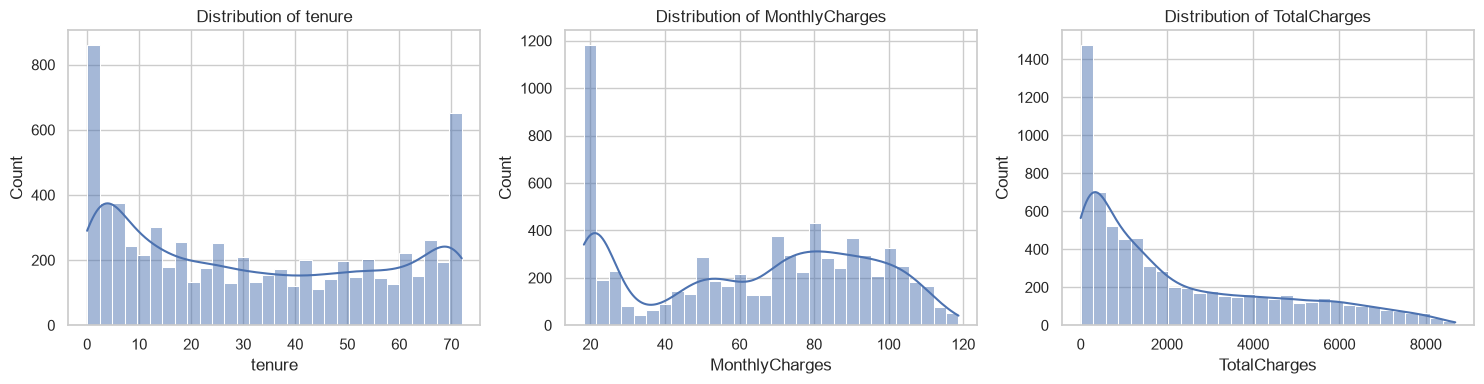

Skewness:
tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64


In [2]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_numeric_distributions.png", dpi=120)
plt.show()

print("Skewness:")
print(df[num_cols].skew().round(2))

**Line by line**
- `plt.subplots(1, 3, ...)`: creates 1 row of 3 empty chart areas (`axes`). `figsize` sets the size.
- `zip(axes, num_cols)`: pairs each chart area with a column name so the loop draws one chart per column.
- `sns.histplot(..., bins=30, kde=True)`: histogram with 30 bars. `kde=True` adds a smooth line showing the overall shape.
- `plt.tight_layout()`: stops titles overlapping. `savefig` writes the image to a file. `show()` displays it.
- `.skew()`: a number for how lopsided the distribution is. 0 = symmetric, positive = long tail to the right.

**How to read the output**
- **`tenure`:** a high bar at the very start (many brand-new customers) and another at the end (loyal long-term customers). It is *not* bell-shaped. A good reminder that real data is rarely tidy.
- **`MonthlyCharges`:** one big group at the cheapest plans (about $20) and a wide spread above.
- **`TotalCharges`:** strongly right-skewed (skew about 0.96). Most customers have paid little, a few have paid a lot. This makes sense: it grows with tenure, and many customers are recent.

## Step 3: Numeric features vs. churn

Do customers who left look different from those who stayed? A **box plot** shows the median and spread for each group.

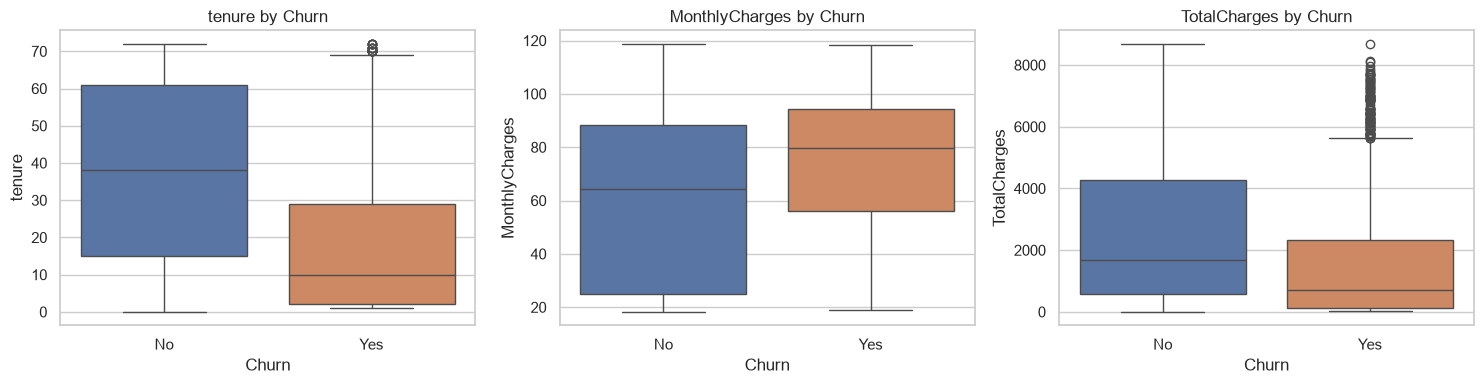

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0            64.4        1679.5
Yes      10.0            79.6         703.6


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax, hue="Churn", legend=False)
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_numeric_vs_churn.png", dpi=120)
plt.show()

print(df.groupby("Churn")[num_cols].median().round(1))

**Line by line**
- `sns.boxplot(data=df, x="Churn", y=col)`: one box per group. The line inside the box is the median, the box covers the middle 50% of values, and the whiskers and dots show the extremes.
- `df.groupby("Churn")[num_cols].median()`: splits the rows by Churn value and takes the median of each numeric column in each group.

**How to read the output**
- **`tenure`:** customers who left have a median tenure of about **10 months**, against about **38** for those who stayed. **The strongest signal so far.** Churn happens early.
- **`MonthlyCharges`:** customers who left pay more (median about $80 vs $64). Higher bills, more churn.
- **`TotalCharges`:** lower for churners, but this mostly just reflects their short tenure.
- Notice that `TotalCharges` mixes two effects: how long they stayed and how much they pay. We will return to this.

## Step 4: Categorical features vs. churn

For each category we compute the **churn rate**: the percentage of customers in that group who churned.
Because `ChurnFlag` is 1/0, the rate is just the mean of `ChurnFlag` per group.

In [4]:
def churn_rate_by(col):
    # Mean of ChurnFlag per group, expressed as a percentage.
    return (df.groupby(col)["ChurnFlag"].mean() * 100).round(1).sort_values(ascending=False)

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(f"--- {col} ---")
    print(churn_rate_by(col))
    print()

--- Contract ---
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64

--- InternetService ---
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: ChurnFlag, dtype: float64

--- PaymentMethod ---
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64

--- TechSupport ---
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: ChurnFlag, dtype: float64



**Line by line**
- `def churn_rate_by(col):` defines a small reusable function: *input* = a column name, *output* = churn rate % for each of its groups.
- `.groupby(col)["ChurnFlag"].mean()`: the average of 0/1 values equals the share of 1s.
- `.sort_values(ascending=False)`: highest churn rate first.

**How to read the output** (all numbers are percent churned)
- **Contract:** Month-to-month about **43%**, one year about **11%**, two year about **3%**. Huge differences. People on long contracts rarely leave, which makes sense since they are locked in.
- **InternetService:** Fiber optic about **42%**, DSL about **19%**, no internet about **7%**. Fiber customers churn far more, perhaps due to price (consistent with higher MonthlyCharges) or service quality. EDA tells us *that*, not *why*.
- **PaymentMethod:** Electronic check about **45%**, the other methods 15-19%.
- **TechSupport:** customers *without* tech support churn about **42%** vs. about **15%** with it.

Now let's draw this for many categorical features at once to compare.

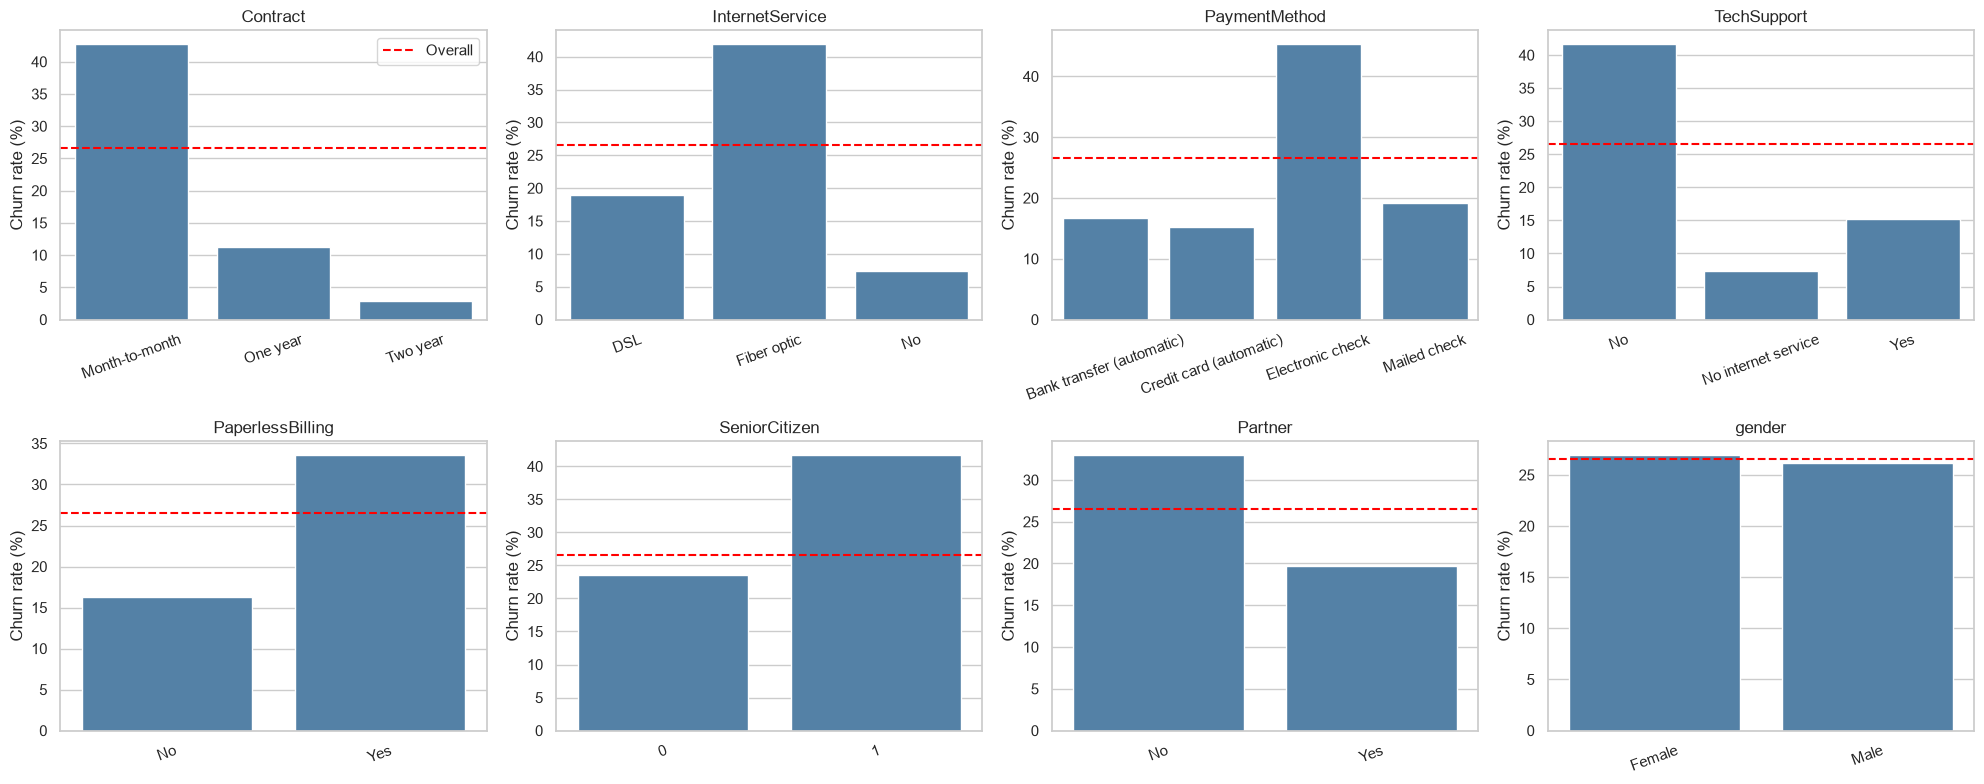

In [5]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "PaperlessBilling", "SeniorCitizen", "Partner", "gender"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rates = df.groupby(col)["ChurnFlag"].mean() * 100
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color="steelblue")
    ax.axhline(df["ChurnFlag"].mean() * 100, color="red", linestyle="--", label="Overall")
    ax.set_title(col)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_churn_rate_by_category.png", dpi=120)
plt.show()

**Line by line**
- `axes.ravel()`: flattens the 2×4 grid into a simple list so we can loop over it.
- `sns.barplot(x=..., y=...)`: one bar per group, with height equal to the churn rate. `.astype(str)` makes the labels text so numbers like 0 and 1 are shown as labels.
- `ax.axhline(...)`: draws the **overall** churn rate (about 26.5%) as a red dashed line. A bar above the line means "churns more than average".

**How to read the output**
- Strong effects: `Contract`, `InternetService`, `PaymentMethod`, `TechSupport`.
- Moderate: `PaperlessBilling` (higher with paperless), `SeniorCitizen` (seniors churn more), `Partner`.
- **`gender` shows essentially no difference** (about 27% vs 26%). It looks like a useless feature, which is fine. Not every feature matters.

**Caution:** a bar is only trustworthy if the group is big enough. Let's check group sizes for one feature.

In [6]:
print(df["SeniorCitizen"].value_counts())
print(df["PaymentMethod"].value_counts())

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


Each group has hundreds of customers or more, so the rates are reliable. (A rate based on 3 customers would not be.)

## Step 5: Correlations between numeric features

A **correlation matrix** gives the correlation for every pair of numeric columns. A **heatmap** colours it so patterns stand out. We include `ChurnFlag` so we can see how each number relates to the target.

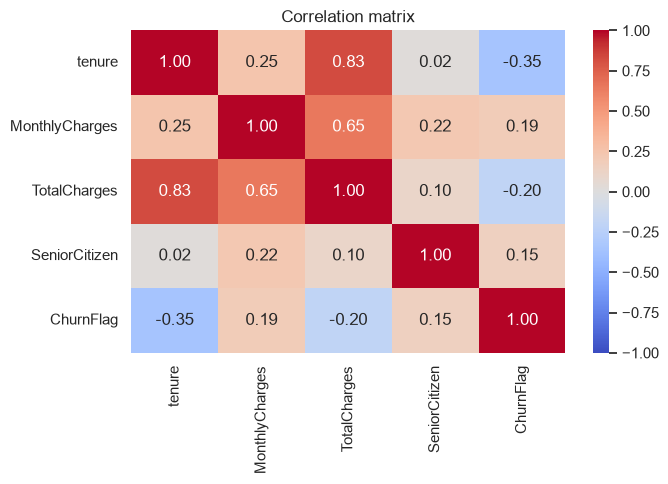

In [7]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]
corr = df[corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_correlation_heatmap.png", dpi=120)
plt.show()

**Line by line**
- `df[corr_cols].corr()`: computes the correlation of every pair of columns. *Output:* a square table of values from −1 to +1, with 1.0 on the diagonal (every column correlates perfectly with itself).
- `sns.heatmap(..., annot=True)`: shows the matrix as colours, with the numbers written in each cell. `vmin/vmax` fix the colour scale to the full −1..+1 range. `cmap="coolwarm"` makes red = positive, blue = negative.

**How to read the output**
- **`tenure` vs. `TotalCharges` = 0.83**: strong. Total spend mostly measures how long you stayed. These two overlap a lot (**multicollinearity**). Some models, such as Logistic Regression, can be unstable with highly overlapping features. We will think about this in feature selection.
- **`MonthlyCharges` vs. `TotalCharges` = 0.65**: moderate, for the same reason.
- **Against churn (`ChurnFlag`):** `tenure` −0.35 (longer stay → less churn), `MonthlyCharges` +0.19, `SeniorCitizen` +0.15, `TotalCharges` −0.20.
- No single number is strongly correlated with churn. Churn depends on a *combination* of features, which is what ML models are good at.

**Remember:** this only covers numeric features and straight-line links. Contract type, the strongest predictor above, does not appear here at all.

## Step 6: Summary of insights

| Insight | Evidence | What we do next |
|---|---|---|
| Customers churn **early** | Median tenure 10 vs 38 months | Keep `tenure` as a key feature |
| **Month-to-month** contracts churn a lot | 43% vs 11% vs 3% | Encode `Contract` carefully (notebook 06) |
| **Fiber optic** and **electronic check** churn more | 42% and 45% | Categorical encoding |
| **No tech support** → more churn | 42% vs 15% | Possibly combine service columns (notebook 07) |
| `gender` has almost no effect | 27% vs 26% | Candidate to drop (notebook 07) |
| `tenure` and `TotalCharges` overlap | Correlation 0.83 | Consider in feature selection |
| `TotalCharges` is skewed | Skew 0.96 | Check outliers and scaling |

**Next:** `04_outliers`: find extreme values and decide what to do with them.

---
## Exercise

1. Compute the churn rate for `Partner` and for `Dependents` (use `churn_rate_by`). Which has the bigger gap?
2. Draw a histogram of `tenure` coloured by `Churn` (hint: `sns.histplot(data=df, x="tenure", hue="Churn", bins=30)`). In one sentence, describe what you see.
3. Create a new column `HasLongTenure` that is True when tenure is above 24 months. What is the churn rate for each group?
4. **Think:** a colleague says "fiber optic causes churn, so let's remove fiber optic". What is wrong with this reasoning?

In [8]:
# Exercise 1

In [9]:
# Exercise 2